In [1]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

DATA_PATH = Path("..") / "opsd-time_series-2020-10-06"

In [2]:
# loading the data
df_raw = pd.read_csv(DATA_PATH / "time_series_60min_singleindex.csv")
df_raw.head()

,utc_timestamp,cet_cest_timestamp,AT_load_actual_entsoe_transparency,AT_load_forecast_entsoe_transparency,AT_price_day_ahead,AT_solar_generation_actual,AT_wind_onshore_generation_actual,BE_load_actual_entsoe_transparency,BE_load_forecast_entsoe_transparency,BE_solar_generation_actual,...,SI_load_actual_entsoe_transparency,SI_load_forecast_entsoe_transparency,SI_solar_generation_actual,SI_wind_onshore_generation_actual,SK_load_actual_entsoe_transparency,SK_load_forecast_entsoe_transparency,SK_solar_generation_actual,SK_wind_onshore_generation_actual,UA_load_actual_entsoe_transparency,UA_load_forecast_entsoe_transparency
0,2014-12-31T23:00:00Z,2015-01-01T00:00:00+0100,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2015-01-01T00:00:00Z,2015-01-01T01:00:00+0100,5946.0,6701.0,35.0,NaN,69.0,9484.0,9897.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2015-01-01T01:00:00Z,2015-01-01T02:00:00+0100,5726.0,6593.0,45.0,NaN,64.0,9152.0,9521.0,NaN,...,1045.47,816.0,NaN,1.17,2728.0,2860.0,3.8,NaN,NaN,NaN
3,2015-01-01T02:00:00Z,2015-01-01T03:00:00+0100,5347.0,6482.0,41.0,NaN,65.0,8799.0,9135.0,NaN,...,1004.79,805.0,NaN,1.04,2626.0,2810.0,3.8,NaN,NaN,NaN
4,2015-01-01T03:00:00Z,2015-01-01T04:00:00+0100,5249.0,6454.0,38.0,NaN,64.0,8567.0,8909.0,NaN,...,983.79,803.0,NaN,1.61,2618.0,2780.0,3.8,NaN,NaN,NaN


In [3]:
# I'm just gonna keep the colums for Czechia and the cet_cest timestamp as that's the one relevant for Czechia
COLUMNS_TO_KEEP = ["cet_cest_timestamp",
                   "CZ_load_actual_entsoe_transparency",
                   "CZ_solar_generation_actual",
                   "CZ_wind_onshore_generation_actual"]
df_czech = df_raw[COLUMNS_TO_KEEP]
df_czech.head()

,cet_cest_timestamp,CZ_load_actual_entsoe_transparency,CZ_solar_generation_actual,CZ_wind_onshore_generation_actual
0,2015-01-01T00:00:00+0100,NaN,NaN,NaN
1,2015-01-01T01:00:00+0100,NaN,NaN,NaN
2,2015-01-01T02:00:00+0100,5957.57,NaN,38.48
3,2015-01-01T03:00:00+0100,5878.87,NaN,56.20
4,2015-01-01T04:00:00+0100,5827.80,NaN,71.21


In [4]:
# converting dates into a datetime format and setting it as the index and then dropping it
df_czech.index = (pd.to_datetime(df_czech["cet_cest_timestamp"], utc=True).dt.tz_convert("Europe/Prague"))
df_czech = df_czech.drop("cet_cest_timestamp", axis = 1)
df_czech.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 50401 entries, 2015-01-01 00:00:00+01:00 to 2020-10-01 01:00:00+02:00
Data columns (total 3 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   CZ_load_actual_entsoe_transparency  50291 non-null  float64
 1   CZ_solar_generation_actual          50365 non-null  float64
 2   CZ_wind_onshore_generation_actual   50385 non-null  float64
dtypes: float64(3)
memory usage: 1.5 MB


## Getting the highest load day in each year
My task for submission is to upload a csv containing the dates of the highest load day for each year.

In [5]:
# now I'm gonna get the highest load day for each year

load = df_czech["CZ_load_actual_entsoe_transparency"]

# getting the daily sum for each day
daily_load = load.resample("D").sum()

# grouping by year and getting the id of the highest load days
max_days = daily_load.groupby(daily_load.index.year).idxmax()

# keeping just the dates to fit the submission format
max_days = max_days.dt.date

In [6]:
# storing the dates to a csv file
max_days.to_csv(DATA_PATH / "max_days.csv", header = False, index = False)

## EDA
Here I'll perform some analysis and get some insights into the data.
First I'll check the daily load.

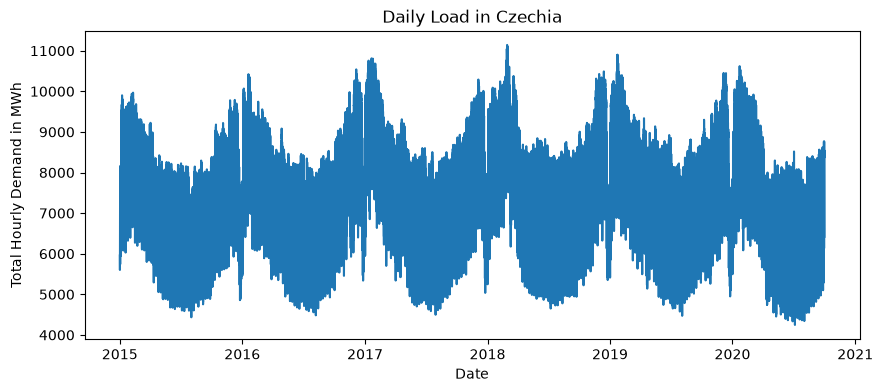

In [7]:
# Now I'll just print a bunch of plots to get some image about the daily load
fig, ax = plt.subplots(figsize = (10, 4))
ax.plot(df_czech.index, df_czech["CZ_load_actual_entsoe_transparency"])
ax.set_title("Daily Load in Czechia")
ax.set_xlabel("Date")
ax.set_ylabel("Total Hourly Demand in MWh")
plt.show()

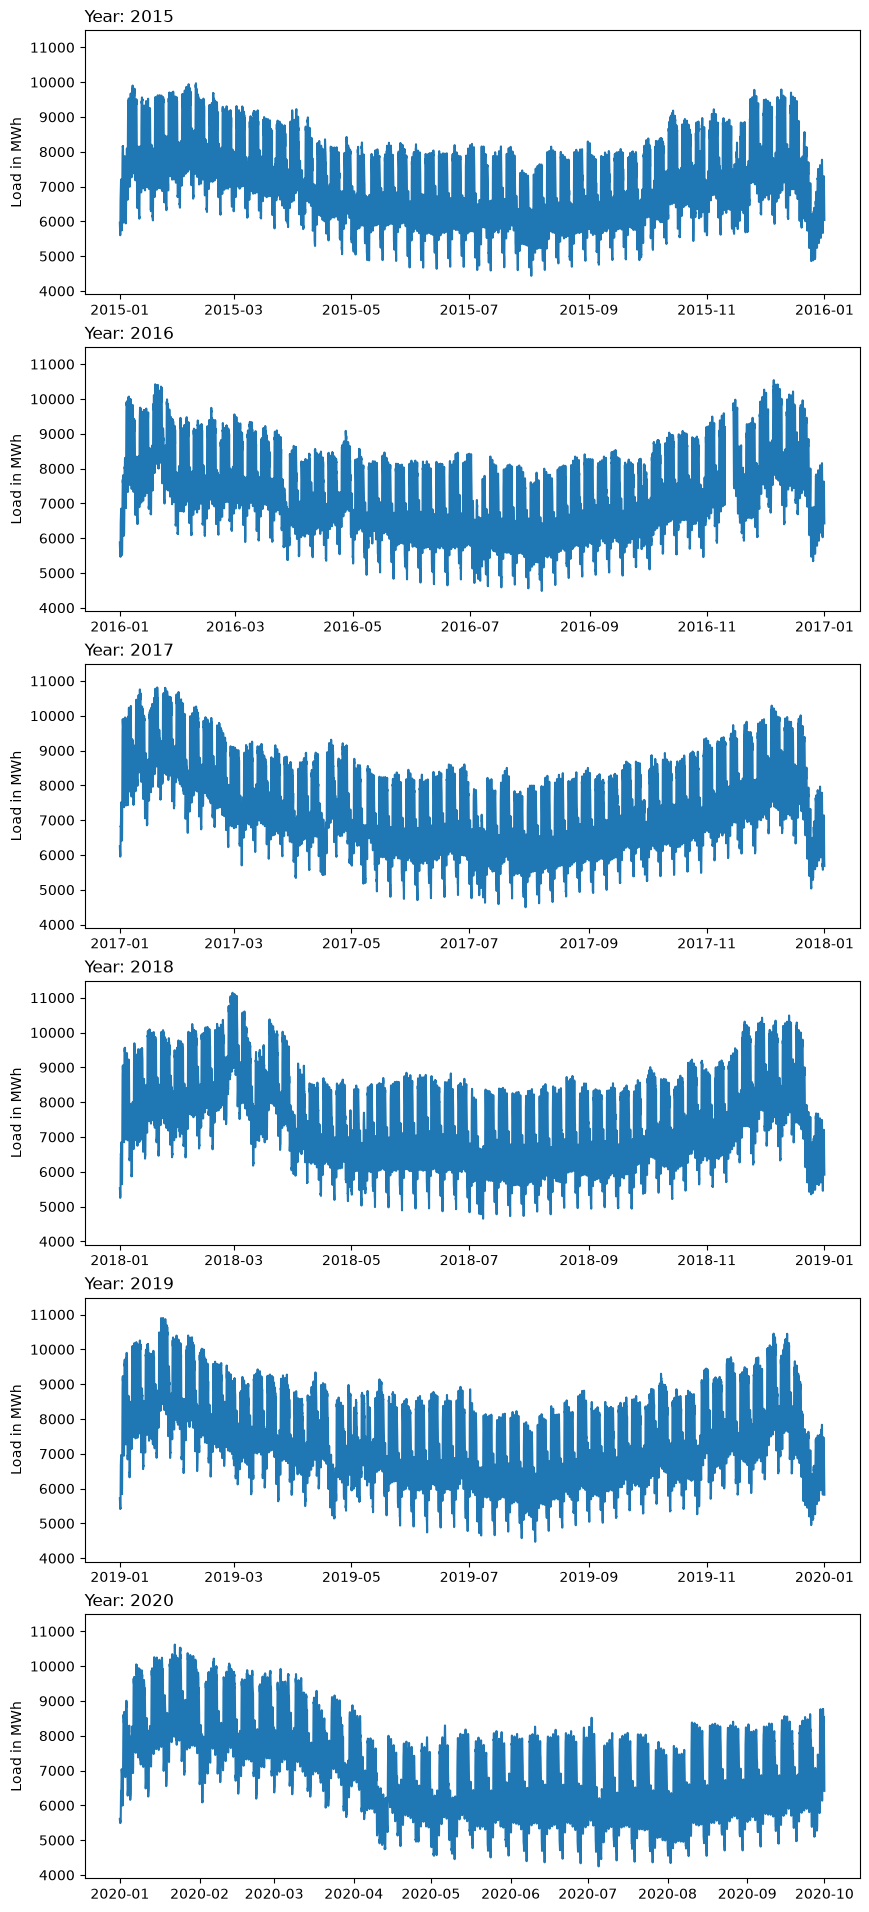

In [8]:
years = df_czech.index.year.unique()

fig, axes = plt.subplots(len(years), 1, figsize = (10, 24), sharey = True)

for ax, year in zip(axes, years):
    ax.plot(df_czech.index[df_czech.index.year == year], df_czech["CZ_load_actual_entsoe_transparency"][df_czech.index.year == year])
    ax.set_title(f'Year: {year}', loc = "left")
    ax.set_ylabel("Load in MWh")
    
plt.show()

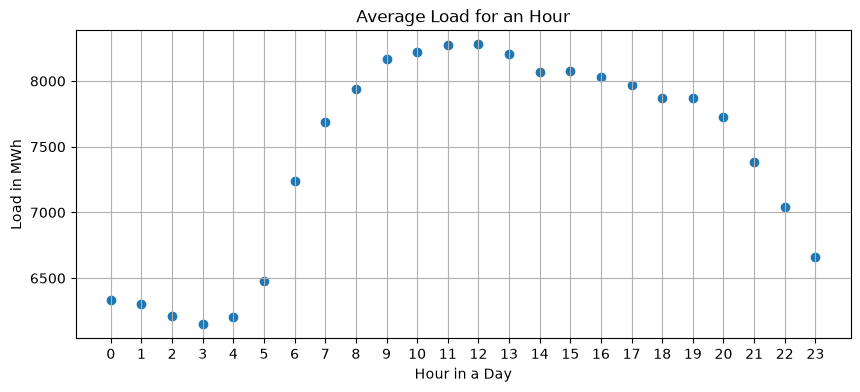

In [9]:
# here I'm gonna plot the average load for every hour in a day
hourly_load = df_czech["CZ_load_actual_entsoe_transparency"].groupby(df_czech.index.hour).mean()

fig, ax = plt.subplots(figsize=(10, 4))
ax.scatter(hourly_load.index, hourly_load.values)
ax.set_xticks(range(24))
ax.set_xlabel("Hour in a Day")
ax.set_ylabel("Load in MWh")
ax.grid(True)
ax.set_title("Average Load for an Hour")
plt.show()

Text(0.5, 1.0, 'Average Load for a Day of the Week')

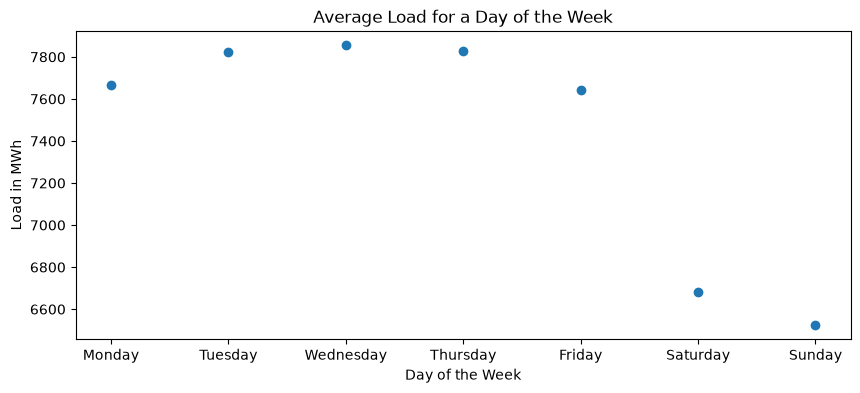

In [10]:
daily_load = df_czech["CZ_load_actual_entsoe_transparency"].groupby(df_czech.index.day_name()).mean()
daily_load = daily_load[["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]]
fig, ax = plt.subplots(figsize = (10, 4))
ax.scatter(daily_load.index, daily_load.values)
ax.set_ylabel("Load in MWh")
ax.set_xlabel("Day of the Week")
ax.set_title("Average Load for a Day of the Week")

In [11]:
df_czech[df_czech["CZ_load_actual_entsoe_transparency"].isna()]
print(df_czech[df_czech["CZ_load_actual_entsoe_transparency"].isna()].index)

DatetimeIndex(['2015-01-01 00:00:00+01:00', '2015-01-01 01:00:00+01:00',
               '2016-11-10 08:00:00+01:00', '2016-11-10 09:00:00+01:00',
               '2016-11-10 10:00:00+01:00', '2016-11-10 11:00:00+01:00',
               '2016-11-10 12:00:00+01:00', '2016-11-10 13:00:00+01:00',
               '2016-11-10 14:00:00+01:00', '2016-11-10 15:00:00+01:00',
               ...
               '2016-11-14 10:00:00+01:00', '2016-11-14 11:00:00+01:00',
               '2016-11-14 12:00:00+01:00', '2016-11-14 13:00:00+01:00',
               '2016-11-14 14:00:00+01:00', '2016-11-14 15:00:00+01:00',
               '2017-11-09 09:00:00+01:00', '2017-11-09 10:00:00+01:00',
               '2017-11-09 11:00:00+01:00', '2020-10-01 01:00:00+02:00'],
              dtype='datetime64[us, Europe/Prague]', name='cet_cest_timestamp',
              length=110, freq=None)


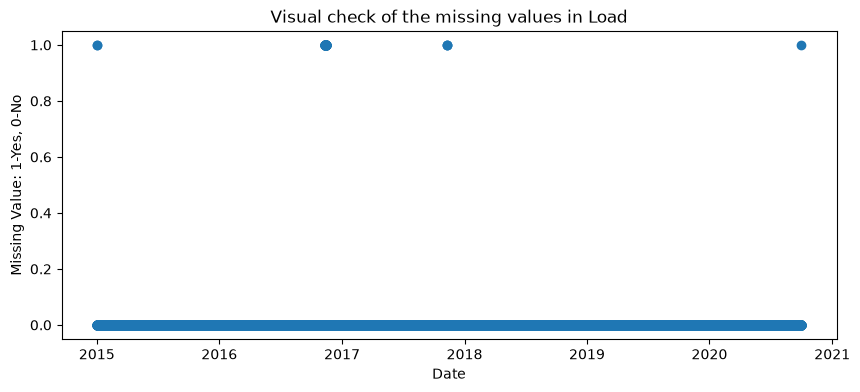

In [14]:
fig, ax = plt.subplots(figsize = (10, 4))

ax.scatter(df_czech.index, df_czech["CZ_load_actual_entsoe_transparency"].isna())
ax.set_ylabel("Missing Value: 1-Yes, 0-No")
ax.set_xlabel("Date")
ax.set_title("Visual check of the missing values in Load")
plt.show()


## Detrending using differentiation
Now I'm gonna detrend the timeserie using the differentiation and explore the detrended timeserie.

In [19]:
load_detrended = []
for i in range(len(df_czech) - 1):
    diff = df_czech['CZ_load_actual_entsoe_transparency'].iloc[i+1] - df_czech['CZ_load_actual_entsoe_transparency'].iloc[i]
    load_detrended.append(diff)

In [23]:
load_detrended_series = pd.Series(load_detrended, index = df_czech[1:].index)

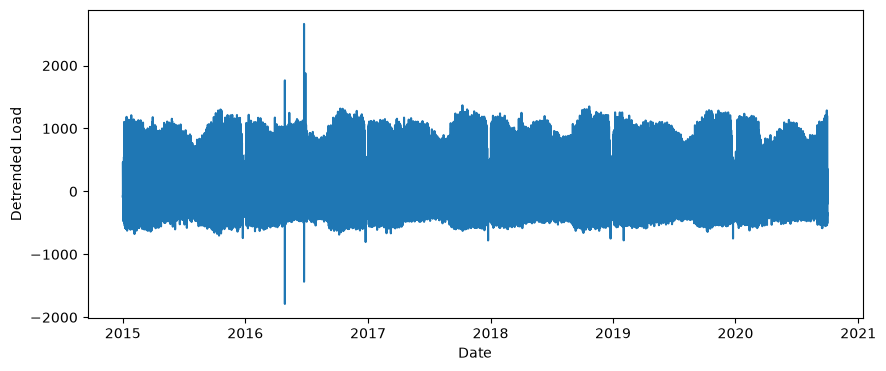

In [27]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(load_detrended_series.index, load_detrended_series.values)
ax.set_ylabel('Detrended Load')
ax.set_xlabel('Date')
plt.show()